# Tugas Praktikum 6: Clustering (Advance)
**Nama:** Daffa Aufa Afif  
**NRP:** 5054251022  
**Mata Kuliah:** Data Mining  
**Dataset:** Palmer Archipelago (Antarctica) Penguin Data  


## Imports


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import dendrogram, linkage

/home/dff/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Dataset
Dataset yang digunakan adalah *Palmer Penguins* (Horst, Hill, & Gorman, 2020) yang mencatat observasi morfologi penguin di tiga pulau di Kepulauan Palmer, Antartika.


In [2]:
url = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(url)

print(df.shape)
display(df.head())
display(df.info())

(344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


None

## EDA dan Preprocessing
1. Memeriksa jumlah nilai kosong (`.isna().sum()`) pada setiap kolom.
2. Menghapus baris yang memiliki nilai kosong pada salah satu dari empat kolom numerik utama (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`) atau pada kolom `species`.
3. Menampilkan statistik deskriptif sebelum standardisasi dan memperhatikan disparitas skala antar kolom.
4. Menampilkan jumlah baris sebelum vs sesudah pembersihan, serta distribusi spesies.
5. Membuat scatter plot awal `flipper_length_mm` terhadap `bill_length_mm` dengan warna berdasarkan spesies asli.


In [3]:
print("Jumlah Missing Values per Kolom:")
print(df.isna().sum())


Jumlah Missing Values per Kolom:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [4]:
# Seleksi fitur numerik clustering dan label pembanding
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target = 'species'


df_clean = df.dropna(subset=features + [target]).copy()

print(f"Jumlah baris sebelum pembersihan: {len(df)}")
print(f"Jumlah baris setelah pembersihan : {len(df_clean)}")
print(f"Baris yang dihapus               : {len(df) - len(df_clean)}")

print("\nDistribusi Data per Spesies Pembanding:")
display(df_clean[target].value_counts().to_frame(name='Jumlah Sampel'))


Jumlah baris sebelum pembersihan: 344
Jumlah baris setelah pembersihan : 342
Baris yang dihapus               : 2

Distribusi Data per Spesies Pembanding:


,Jumlah Sampel
species,
Adelie,151
Gentoo,123
Chinstrap,68


In [5]:
display(df_clean[features].describe().T)


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


**Observasi Perbedaan Skala:**  
Terlihat perbedaan skala yang sangat signifikan antar fitur:
- `body_mass_g` memiliki rentang nilai 2700 hingga 6300 g (orde ribuan, standar deviasi ~802 g).
- `flipper_length_mm` berkisar antara 172 hingga 231 mm (orde ratusan, standar deviasi ~14 mm).
- `bill_length_mm` berkisar antara 32.1 hingga 59.6 mm (orde puluhan, standar deviasi ~5.46 mm).
- `bill_depth_mm` berkisar antara 13.1 hingga 21.5 mm (orde belasan, standar deviasi ~1.97 mm).

Apabila data tidak distandardisasi, metrik jarak Euclidean akan didominasi secara mutlak oleh `body_mass_g`, sehingga mengaburkan kontribusi fitur dimensi paruh dan sirip yang justru memiliki daya pembeda taksonomis yang krusial.


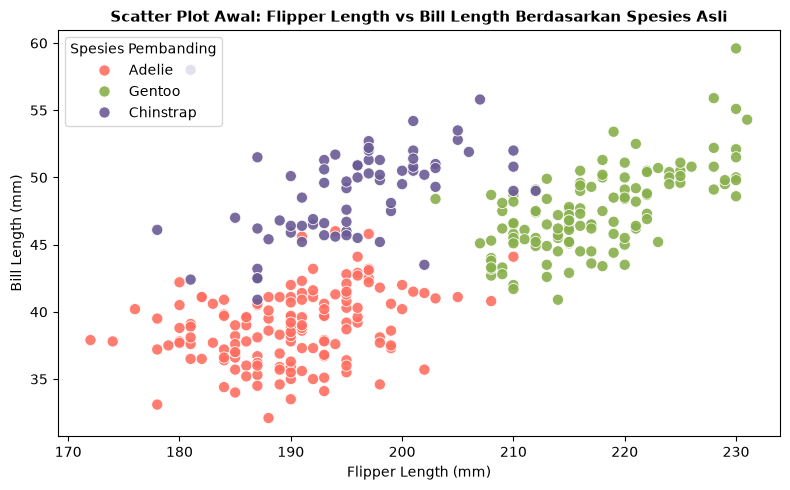

In [6]:
plt.figure(figsize=(8, 5))
palette = {'Adelie': '#FF6F61', 'Chinstrap': '#6B5B95', 'Gentoo': '#88B04B'}

sns.scatterplot(
    data=df_clean,
    x='flipper_length_mm',
    y='bill_length_mm',
    hue='species',
    palette=palette,
    s=65,
    alpha=0.9,
    edgecolor='white'
)
plt.title('Scatter Plot Awal: Flipper Length vs Bill Length Berdasarkan Spesies Asli', fontsize=11, fontweight='bold')
plt.xlabel('Flipper Length (mm)', fontsize=10)
plt.ylabel('Bill Length (mm)', fontsize=10)
plt.legend(title='Spesies Pembanding', loc='upper left')
plt.tight_layout()
plt.show()


## Standardisasi Data
Empat fitur numerik diekstraksi ke dalam matriks $X$, sedangkan kolom `species` dipisahkan sebagai array $y$.  
Standardisasi dilakukan menggunakan *z-score* via `StandardScaler`, mentransformasi setiap fitur sehingga memiliki rata-rata $\mu = 0$ dan standar deviasi $\sigma = 1$:
$$z = \frac{x - \mu}{\sigma}$$
Seluruh algoritma clustering lanjutan akan dijalankan secara konsisten pada data hasil standardisasi ini.


In [7]:
X = df_clean[features].values
y = df_clean[target].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled_summary = pd.DataFrame(X_scaled, columns=features)
print("Statistik Deskriptif Fitur Setelah Standardisasi (Mean & Std Dev):")
display(pd.DataFrame({
    'Mean (Setelah Standarisasi)': df_scaled_summary.mean().round(4),
    'Std Dev (Setelah Standarisasi)': df_scaled_summary.std().round(4)
}))


Statistik Deskriptif Fitur Setelah Standardisasi (Mean & Std Dev):


,Mean (Setelah Standarisasi),Std Dev (Setelah Standarisasi)
bill_length_mm,0.0,1.0015
bill_depth_mm,0.0,1.0015
flipper_length_mm,-0.0,1.0015
body_mass_g,0.0,1.0015


## Advance Clustering
Empat algoritma clustering lanjutan diterapkan pada dataset:
1. **Agglomerative Clustering** (Hierarchical): menggunakan $k=3$ dan linkage Ward (*Ward's minimum variance criterion*).
2. **DBSCAN** (Density-Based): pengujian parameter jarak $\epsilon$ (*eps*) dari $0.3$ hingga $1.2$ dengan $MinPts=5$.
3. **Gaussian Mixture Models (GMM)** (Model-Based / Probabilistic): menggunakan $k=3$ komponen Gaussian dan kovarians penuh (*full covariance*).
4. **Spectral Clustering** (Graph / Manifold-Based): menggunakan $k=3$ dan matriks afinitas RBF (*Radial Basis Function*).


### 1. Agglomerative Hierarchical Clustering
Metode linkage yang digunakan adalah **Ward Linkage** (`linkage='ward'`). Linkage Ward meminimalkan penambahan variansi total dalam kluster (*within-cluster sum of squares*) pada setiap iterasi penggabungan, sehingga menghasilkan kluster yang kompak dan seimbang secara ukuran.


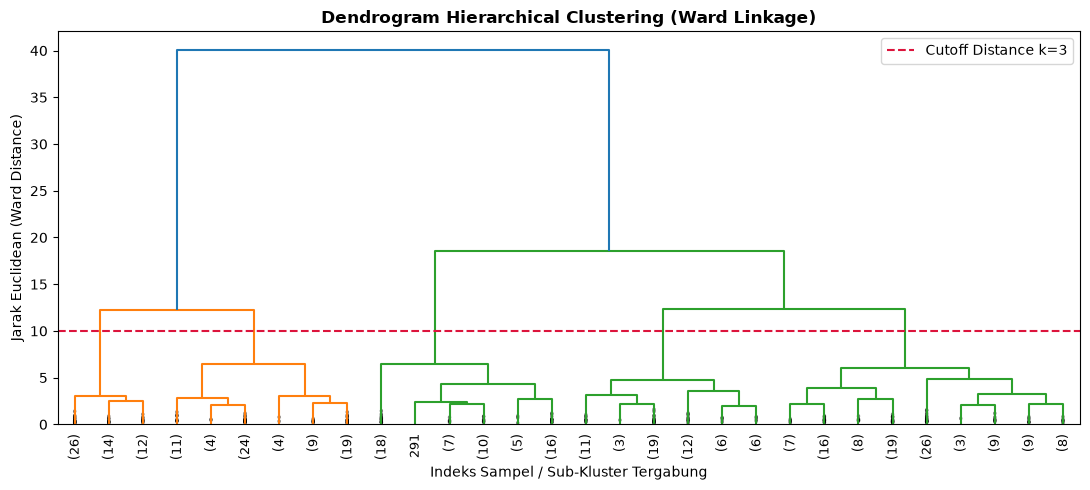

Distribusi anggota kluster Agglomerative: [162 123  57]


In [8]:
# Pembuatan Dendrogram
plt.figure(figsize=(11, 5))
Z = linkage(X_scaled, method='ward')
dend = dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.axhline(y=10.0, color='crimson', linestyle='--', linewidth=1.5, label='Cutoff Distance k=3')
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage)', fontsize=12, fontweight='bold')
plt.xlabel('Indeks Sampel / Sub-Kluster Tergabung', fontsize=10)
plt.ylabel('Jarak Euclidean (Ward Distance)', fontsize=10)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Fitting Model Agglomerative
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)
print(f"Distribusi anggota kluster Agglomerative: {np.bincount(agg_labels)}")


### 2 Density-Based Spatial Clustering (DBSCAN)
DBSCAN mengelompokkan data berdasarkan densitas titik lokal. Sesuai instruksi, kita menguji $\epsilon$ mulai dari $0.5$ dengan $MinPts = 5$, serta mencoba rentang nilai $\epsilon$ lainnya untuk melihat dinamika jumlah kluster dan titik noise.


In [9]:
eps_candidates = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2]
db_tuning_records = []

for eps in eps_candidates:
    dbs_test = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    unique_lbls = set(dbs_test.labels_)
    n_clusters = len(unique_lbls) - (1 if -1 in unique_lbls else 0)
    n_noise = (dbs_test.labels_ == -1).sum()
    db_tuning_records.append({
        'Epsilon (eps)': eps,
        'MinPts': 5,
        'Jumlah Kluster': n_clusters,
        'Jumlah Noise (Outlier)': n_noise,
        'Persentase Noise (%)': round((n_noise / len(X_scaled)) * 100, 2)
    })

df_db_tune = pd.DataFrame(db_tuning_records)
print("Hasil Eksperimen Parameter Epsilon pada DBSCAN:")
display(df_db_tune)


Hasil Eksperimen Parameter Epsilon pada DBSCAN:


,Epsilon (eps),MinPts,Jumlah Kluster,Jumlah Noise (Outlier),Persentase Noise (%)
0,0.3,5,4,317,92.69
1,0.4,5,10,171,50.00
2,0.5,5,4,69,20.18
3,0.6,5,2,33,9.65
4,0.7,5,2,16,4.68
5,0.8,5,2,5,1.46
6,1.0,5,2,1,0.29
7,1.2,5,2,1,0.29


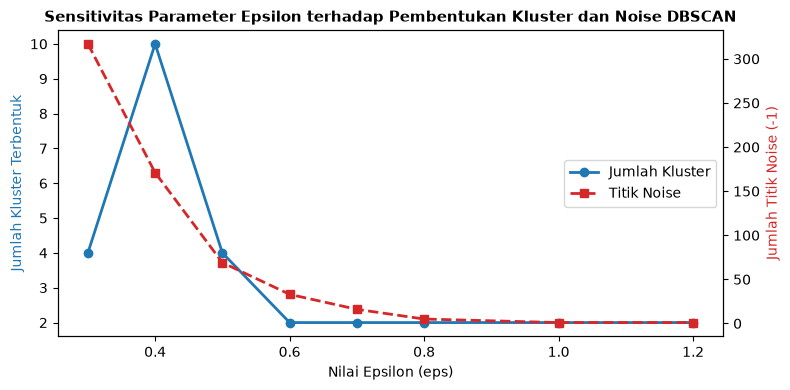

DBSCAN (eps=0.5): Terbentuk 4 kluster dan 69 titik noise.


In [10]:
# Plot Tuning DBSCAN
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()

line1 = ax1.plot(df_db_tune['Epsilon (eps)'], df_db_tune['Jumlah Kluster'], 'o-', color='#1f77b4', linewidth=2, label='Jumlah Kluster')
line2 = ax2.plot(df_db_tune['Epsilon (eps)'], df_db_tune['Jumlah Noise (Outlier)'], 's--', color='#d62728', linewidth=2, label='Titik Noise')

ax1.set_xlabel('Nilai Epsilon (eps)', fontsize=10)
ax1.set_ylabel('Jumlah Kluster Terbentuk', color='#1f77b4', fontsize=10)
ax2.set_ylabel('Jumlah Titik Noise (-1)', color='#d62728', fontsize=10)
plt.title('Sensitivitas Parameter Epsilon terhadap Pembentukan Kluster dan Noise DBSCAN', fontsize=11, fontweight='bold')

lines = line1 + line2
lbls = [l.get_label() for l in lines]
ax1.legend(lines, lbls, loc='center right')
plt.tight_layout()
plt.show()

# Model DBSCAN yang digunakan untuk evaluasi utama (eps=0.5, MinPts=5)
dbscan = DBSCAN(eps=0.5, min_samples=5)
db_labels = dbscan.fit_predict(X_scaled)
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_db_noise = (db_labels == -1).sum()
print(f"DBSCAN (eps=0.5): Terbentuk {n_db_clusters} kluster dan {n_db_noise} titik noise.")


### 3 Gaussian Mixture Models (GMM)
GMM mengasumsikan data dihasilkan dari percampuran sejumlah distribusi Gaussian multi-variat yang masing-masing memiliki parameter vektor rata-rata ($\boldsymbol{\mu}_k$) dan matriks kovarians ($\boldsymbol{\Sigma}_k$). Model ini mampu menangkap kluster dengan bentuk elips, variansi heterogen, dan korelasi antar fitur.


In [11]:
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm_labels = gmm.fit_predict(X_scaled)
print(f"Distribusi anggota kluster GMM: {np.bincount(gmm_labels)}")


Distribusi anggota kluster GMM: [ 67 123 152]


### 4 Spectral Clustering
Spectral Clustering memanfaatkan nilai eigen (*eigenvalues*) dan vektor eigen (*eigenvectors*) dari matriks Laplacian graf kesamaan (*similarity graph*). Metode ini sangat ampuh dalam memetakan data dengan manifold non-linear ke dalam ruang dimensi tereduksi sebelum dilakukan pengelompokan k-means.


In [12]:
spectral = SpectralClustering(n_clusters=3, affinity='rbf', random_state=42)
spectral_labels = spectral.fit_predict(X_scaled)
print(f"Distribusi anggota kluster Spectral Clustering: {np.bincount(spectral_labels)}")


Distribusi anggota kluster Spectral Clustering: [176 123  43]


### Komparasi Scatter Plot Hasil Seluruh Algoritma
Visualisasi scatter plot menampilkan proyeksi dimensi `flipper_length_mm` terhadap `bill_length_mm`. Titik noise pada DBSCAN (label -1) ditandai dengan simbol silang merah `x` agar mudah diidentifikasi.


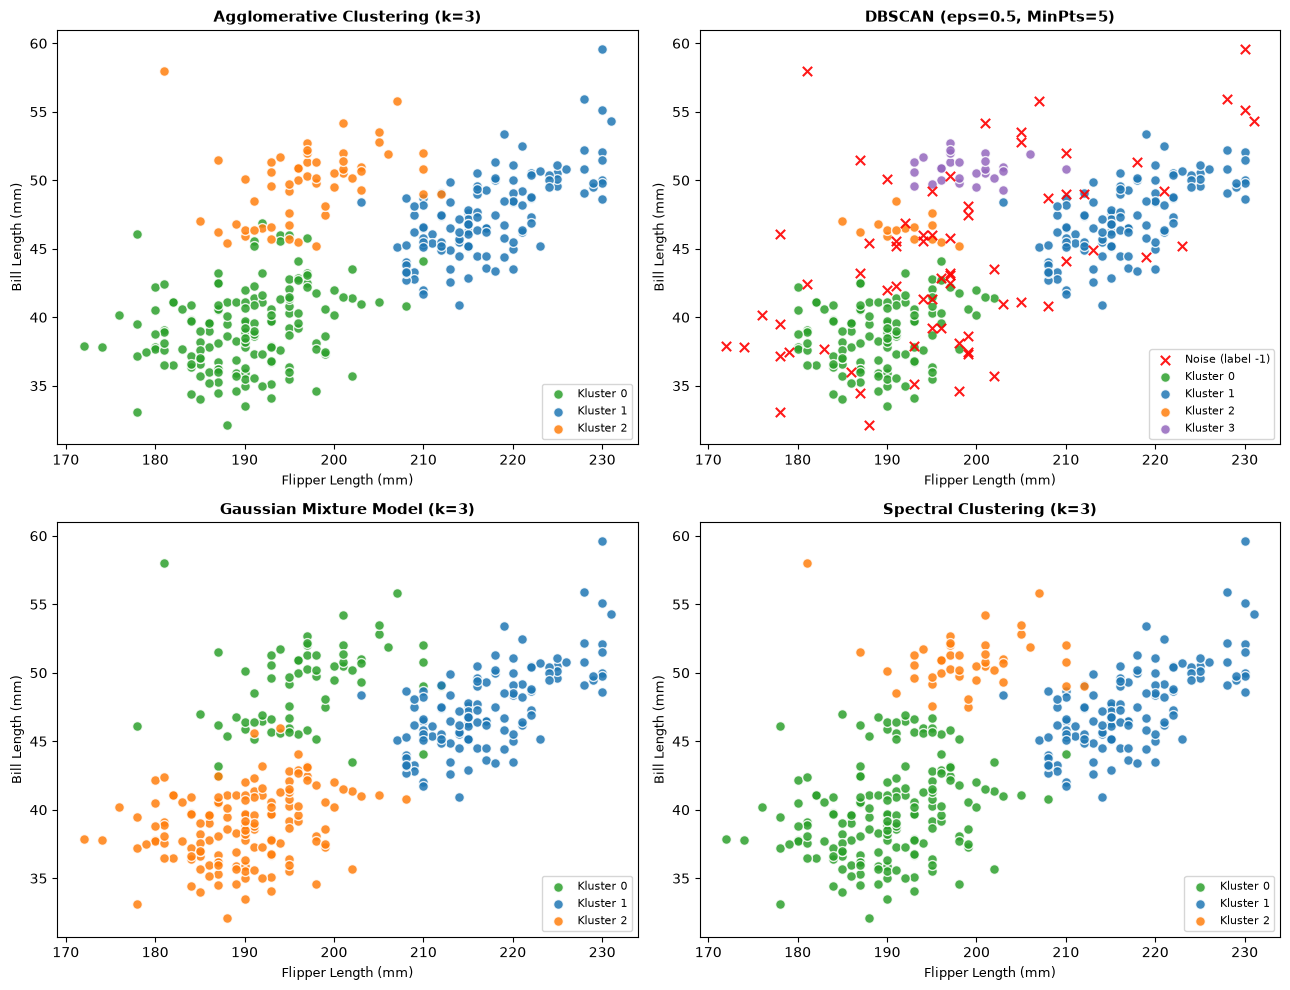

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
cluster_colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#9467bd', '#8c564b']

model_configs = [
    ('Agglomerative Clustering (k=3)', agg_labels, axes[0, 0]),
    ('DBSCAN (eps=0.5, MinPts=5)', db_labels, axes[0, 1]),
    ('Gaussian Mixture Model (k=3)', gmm_labels, axes[1, 0]),
    ('Spectral Clustering (k=3)', spectral_labels, axes[1, 1])
]

for title, lbls, ax in model_configs:
    unique_l = np.unique(lbls)
    for l in unique_l:
        mask = (lbls == l)
        if l == -1:
            ax.scatter(df_clean.loc[mask, 'flipper_length_mm'], df_clean.loc[mask, 'bill_length_mm'],
                       c='red', marker='x', s=45, label='Noise (label -1)', alpha=0.9, zorder=5)
        else:
            color = cluster_colors[l % len(cluster_colors)]
            ax.scatter(df_clean.loc[mask, 'flipper_length_mm'], df_clean.loc[mask, 'bill_length_mm'],
                       c=color, marker='o', s=50, edgecolors='white', alpha=0.85, label=f'Kluster {l}')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Flipper Length (mm)', fontsize=9)
    ax.set_ylabel('Bill Length (mm)', fontsize=9)
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()


## Evaluasi Hasil Clustering dan Uji Kestabilan
Evaluasi komprehensif dilakukan dengan:
1. **Silhouette Score**: mengukur seberapa dekat titik data dengan klusternya sendiri (*cohesion*) dibandingkan dengan kluster terdekat lainnya (*separation*). Khusus DBSCAN, titik noise (-1) dibuang sebelum perhitungan.
2. **Rand Index(RI) dan Normalized Mutual Information(NMI)**: dihitung dengan membandingkan partisi kluster terhadap label spesies taksonomi aktual (`species`).
3. **Uji Kestabilan (Stability Test)**: Setiap algoritma dijalankan ulang pada 90% data yang di-subsample secara acak sebanyak 3 kali (3 iterasi seed). Hasil partisi pada subsample dibandingkan dengan hasil model data penuh menggunakan Rand Index untuk mengukur ketahanan partisi terhadap perturbasi data.


In [14]:
# 1. Perhitungan Evaluasi Internal & Eksternal
def calculate_metrics(labels, X_mat, y_true):
    mask = labels != -1
    noise_count = (labels == -1).sum()
    if len(np.unique(labels[mask])) > 1:
        sil = silhouette_score(X_mat[mask], labels[mask])
    else:
        sil = 0.0
    ri = rand_score(y_true, labels)
    nmi = normalized_mutual_info_score(y_true, labels)
    return sil, ri, nmi, noise_count

models_dict = {
    'Agglomerative (ward)': agg_labels,
    'DBSCAN (eps=0.5)': db_labels,
    'GMM (k=3)': gmm_labels,
    'Spectral Clustering': spectral_labels
}

eval_rows = []
for name, lbls in models_dict.items():
    sil, ri, nmi, noise_cnt = calculate_metrics(lbls, X_scaled, y)
    eval_rows.append({
        'Algoritma': name,
        'Silhouette Score': round(sil, 4),
        'Rand Index': round(ri, 4),
        'NMI': round(nmi, 4),
        'Titik Noise Dibuang': int(noise_cnt)
    })


In [15]:
# 2. Uji Kestabilan (Stability Test) pada 90% Subsample Acak (3 Repetisi)
seeds = [42, 100, 2024]
n_total = len(X_scaled)
n_sub = int(0.9 * n_total)

stability_records = {m: [] for m in models_dict}

for i, seed in enumerate(seeds):
    np.random.seed(seed)
    sub_indices = np.random.choice(n_total, size=n_sub, replace=False)
    sub_X = X_scaled[sub_indices]
    
    # Agglomerative
    sub_agg = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(sub_X)
    stability_records['Agglomerative (ward)'].append(rand_score(agg_labels[sub_indices], sub_agg))
    
    # DBSCAN
    sub_db = DBSCAN(eps=0.5, min_samples=5).fit_predict(sub_X)
    stability_records['DBSCAN (eps=0.5)'].append(rand_score(db_labels[sub_indices], sub_db))
    
    # GMM
    sub_gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=seed).fit_predict(sub_X)
    stability_records['GMM (k=3)'].append(rand_score(gmm_labels[sub_indices], sub_gmm))
    
    # Spectral
    sub_spec = SpectralClustering(n_clusters=3, affinity='rbf', random_state=seed).fit_predict(sub_X)
    stability_records['Spectral Clustering'].append(rand_score(spectral_labels[sub_indices], sub_spec))

# Penggabungan ke tabel evaluasi
for row in eval_rows:
    alg_name = row['Algoritma']
    scores = stability_records[alg_name]
    row['Mean Stability (RI 90%)'] = round(float(np.mean(scores)), 4)
    row['Std Stability'] = round(float(np.std(scores)), 4)

df_summary_eval = pd.DataFrame(eval_rows)
print("Tabel Rangkuman Evaluasi dan Uji Kestabilan Clustering:")
display(df_summary_eval)


Tabel Rangkuman Evaluasi dan Uji Kestabilan Clustering:


,Algoritma,Silhouette Score,Rand Index,NMI,Titik Noise Dibuang,Mean Stability (RI 90%),Std Stability
0,Agglomerative (ward),0.4541,0.9608,0.9007,0,0.9244,0.0623
1,DBSCAN (eps=0.5),0.4235,0.8525,0.6631,69,0.9762,0.0089
2,GMM (k=3),0.4545,0.9817,0.9349,0,0.9972,0.0019
3,Spectral Clustering,0.4624,0.9168,0.8312,0,0.9973,0.0039


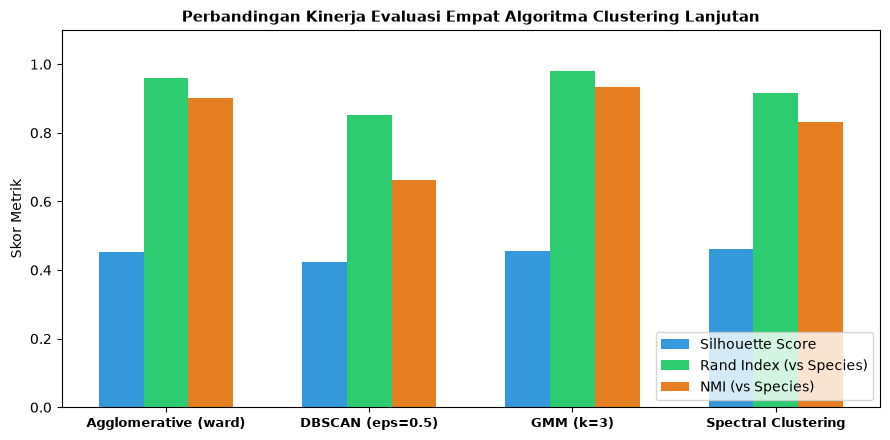

In [16]:
# Visualisasi Bar Plot Komparasi Metrik
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_width = 0.22
idx = np.arange(len(df_summary_eval))

ax.bar(idx - bar_width, df_summary_eval['Silhouette Score'], width=bar_width, label='Silhouette Score', color='#3498db')
ax.bar(idx, df_summary_eval['Rand Index'], width=bar_width, label='Rand Index (vs Species)', color='#2ecc71')
ax.bar(idx + bar_width, df_summary_eval['NMI'], width=bar_width, label='NMI (vs Species)', color='#e67e22')

ax.set_xticks(idx)
ax.set_xticklabels(df_summary_eval['Algoritma'], fontsize=9, fontweight='bold')
ax.set_ylabel('Skor Metrik', fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_title('Perbandingan Kinerja Evaluasi Empat Algoritma Clustering Lanjutan', fontsize=11, fontweight='bold')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()
